<a href="https://colab.research.google.com/github/ali-liyakat/100_days_Deep_Learning/blob/main/06_CNN/08_Transfer_Learning_VGG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transfer Learning with VGG16: Dogs vs Cats Classification

## Objective
Build a binary image classification model using transfer learning with the pretrained VGG16 convolutional neural network.

## Dataset
- **Source:** [Dogs vs Cats — Kaggle](https://www.kaggle.com/datasets/salader/dogsvscats)
- **Training images:** Approximately 20,000
- **Testing images:** Approximately 5,000
- **Classes:** Cats and Dogs

## Methodology
1. Download the dataset using KaggleHub.
2. Load and preprocess images using TensorFlow.
3. Apply data augmentation to training images.
4. Load VGG16 pretrained on ImageNet.
5. Freeze the pretrained convolutional base and train a classification head.
6. Evaluate model performance and visualize training curves.
7. Save the trained model.

**Learning goal:** Understand how pretrained CNNs can be adapted to a new image classification task.

In [1]:
%pip install -q -U kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.4/40.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.3/73.3 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.9/290.9 kB 19.3 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
dataset_path = Path(
    kagglehub.dataset_download("salader/dogsvscats")
)

print("Dataset path:", dataset_path)
print("Contents:", [p.name for p in dataset_path.iterdir()])

Using Colab cache for faster access to the 'dogsvscats' dataset.
Dataset path: /kaggle/input/dogsvscats
Contents: ['test', 'train', 'catsvsdogs']


In [4]:
train_dir = dataset_path / "train"
test_dir = dataset_path / "test"

print("Training directory exists:", train_dir.exists())
print("Testing directory exists:", test_dir.exists())

print("Training classes:", sorted(p.name for p in train_dir.iterdir()))
print("Testing classes:", sorted(p.name for p in test_dir.iterdir()))

Training directory exists: True
Testing directory exists: True
Training classes: ['cats', 'dogs']
Testing classes: ['cats', 'dogs']


In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["cats", "dogs"],
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["cats", "dogs"],
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["cats", "dogs"],
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 20000 files belonging to 2 classes.
Using 16000 files for training.
Found 20000 files belonging to 2 classes.
Using 4000 files for validation.
Found 5000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


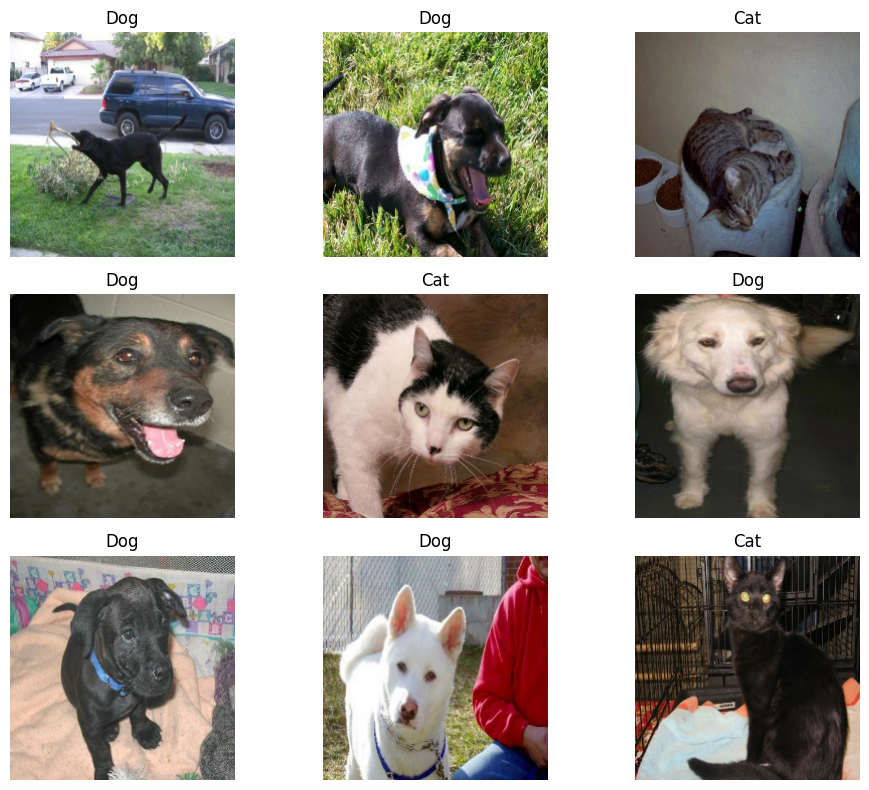

In [6]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))

    label = int(labels[i].numpy()[0])
    plt.title(["Cat", "Dog"][label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Dataset pipelines ready.")

Dataset pipelines ready.


### 1. Feature Extraction Method

In [9]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("VGG16 loaded with ImageNet weights.")
print("Base model trainable:", base_model.trainable)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 loaded with ImageNet weights.
Base model trainable: False


In [10]:
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = layers.Lambda(preprocess_input, name="vgg16_preprocessing")(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name="vgg16_dogs_vs_cats")

model.summary()

Model: "vgg16_dogs_vs_cats"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16_preprocessing (Lambda)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [12]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_vgg16_dogs_vs_cats.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [13]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.9202 - loss: 0.3241
Epoch 1: val_loss improved from None to 0.05492, saving model to best_vgg16_dogs_vs_cats.keras

Epoch 1: finished saving model to best_vgg16_dogs_vs_cats.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 91s 168ms/step - accuracy: 0.9507 - loss: 0.1593 - val_accuracy: 0.9825 - val_loss: 0.0549 - learning_rate: 0.0010
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9698 - loss: 0.0800
Epoch 2: val_loss improved from 0.05492 to 0.04090, saving model to best_vgg16_dogs_vs_cats.keras

Epoch 2: finished saving model to best_vgg16_dogs_vs_cats.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 86s 171ms/step - accuracy: 0.9696 - loss: 0.0836 - val_accuracy: 0.9860 - val_loss: 0.0409 - learning_rate: 0.0010
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9742 - loss: 0.0691
Epoch 3: val_loss did not improve from 0.04090
500/500 ━━━━━━━━━━━━━━━━━━━━ 86s 171ms/step - accuracy: 0.9743 - loss: 0.0695 

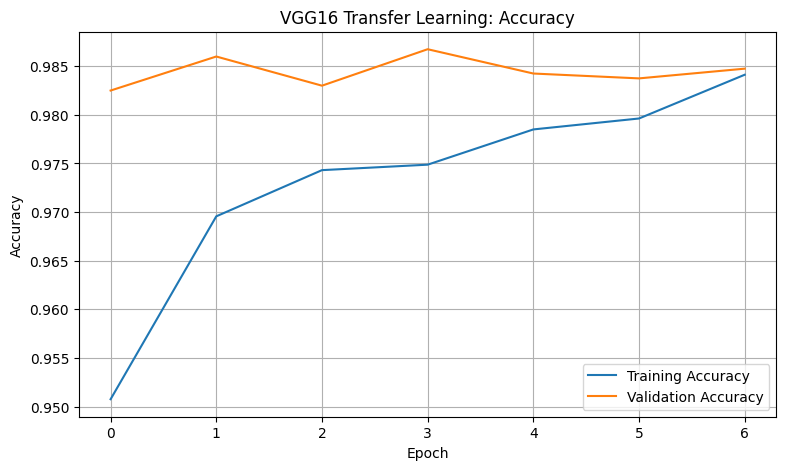

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("VGG16 Transfer Learning: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

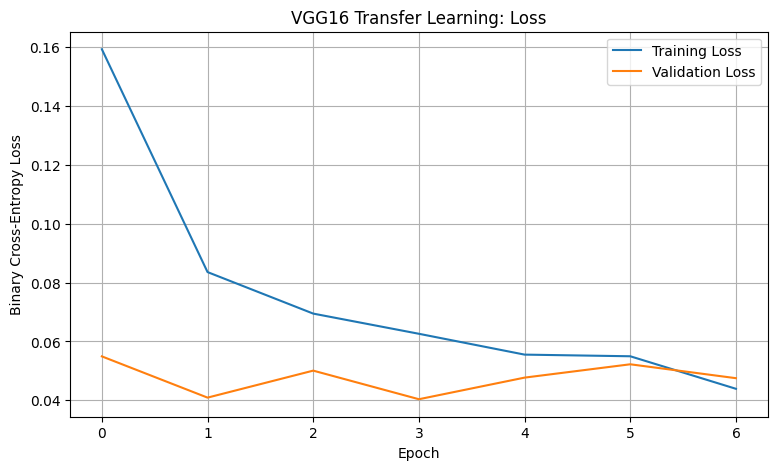

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("VGG16 Transfer Learning: Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 130ms/step - accuracy: 0.9866 - loss: 0.0374
Test Loss: 0.0374
Test Accuracy: 0.9866
Test Accuracy: 98.66%


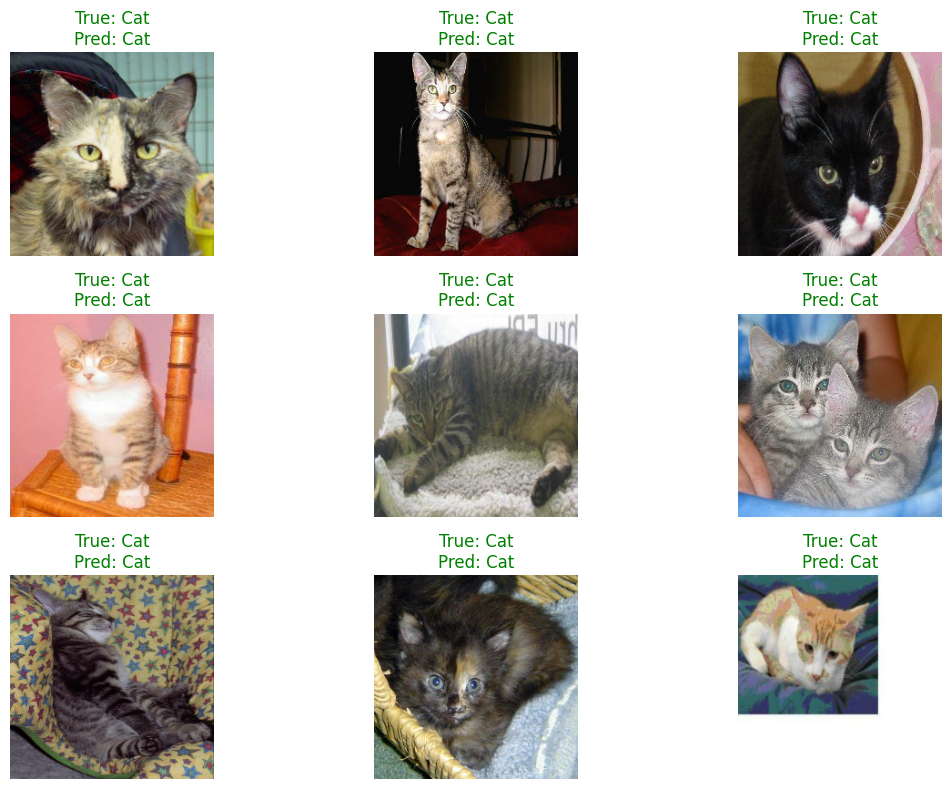

In [17]:
images, labels = next(iter(test_ds))

predictions = model.predict(images, verbose=0).flatten()

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy().astype("uint8"))

    true_label = int(labels[i].numpy()[0])
    predicted_label = int(predictions[i] >= 0.5)

    title_color = "green" if true_label == predicted_label else "red"

    plt.title(
        f"True: {['Cat', 'Dog'][true_label]}\n"
        f"Pred: {['Cat', 'Dog'][predicted_label]}",
        color=title_color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### Fine-Tuning Method

In [18]:
# Unfreeze VGG16 for fine-tuning
base_model.trainable = True

# Keep all layers frozen except the last convolutional block
for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5_")

# Check which layers are trainable
for layer in base_model.layers:
    print(layer.name, "Trainable:", layer.trainable)

print("\nTrainable VGG16 layers:",
      sum(layer.trainable for layer in base_model.layers))

input_layer Trainable: False
block1_conv1 Trainable: False
block1_conv2 Trainable: False
block1_pool Trainable: False
block2_conv1 Trainable: False
block2_conv2 Trainable: False
block2_pool Trainable: False
block3_conv1 Trainable: False
block3_conv2 Trainable: False
block3_conv3 Trainable: False
block3_pool Trainable: False
block4_conv1 Trainable: False
block4_conv2 Trainable: False
block4_conv3 Trainable: False
block4_pool Trainable: False
block5_conv1 Trainable: True
block5_conv2 Trainable: True
block5_conv3 Trainable: True
block5_pool Trainable: True

Trainable VGG16 layers: 4


In [19]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "vgg16_dogs_vs_cats"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16_preprocessing (Lambda)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 7,211,009 (27.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [22]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

finetune_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [23]:
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=finetune_callbacks
)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 98s 195ms/step - accuracy: 0.9864 - loss: 0.0366 - val_accuracy: 0.9895 - val_loss: 0.0347 - learning_rate: 1.0000e-05
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 98s 195ms/step - accuracy: 0.9901 - loss: 0.0274 - val_accuracy: 0.9887 - val_loss: 0.0389 - learning_rate: 1.0000e-05
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.9934 - loss: 0.0200
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
500/500 ━━━━━━━━━━━━━━━━━━━━ 98s 195ms/step - accuracy: 0.9932 - loss: 0.0203 - val_accuracy: 0.9915 - val_loss: 0.0357 - learning_rate: 1.0000e-05
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 98s 195ms/step - accuracy: 0.9942 - loss: 0.0157 - val_accuracy: 0.9915 - val_loss: 0.0345 - learning_rate: 2.0000e-06
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 98s 195ms/step - accuracy: 0.9958 - loss: 0.0134 - val_accuracy: 0.9923 - val_loss: 0.0375 - learning_rate: 2.0000e-06
Restoring model weights from the end of the best epoch: 

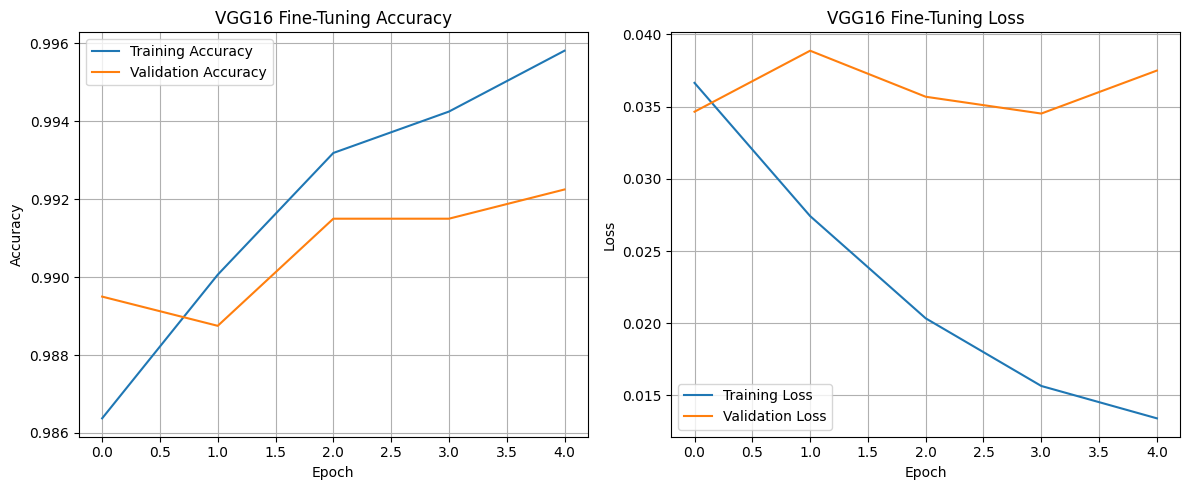

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_finetune.history["accuracy"], label="Training Accuracy")
plt.plot(history_finetune.history["val_accuracy"], label="Validation Accuracy")
plt.title("VGG16 Fine-Tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_finetune.history["loss"], label="Training Loss")
plt.plot(history_finetune.history["val_loss"], label="Validation Loss")
plt.title("VGG16 Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [25]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Fine-tuned Test Loss: {test_loss:.4f}")
print(f"Fine-tuned Test Accuracy: {test_accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 133ms/step - accuracy: 0.9896 - loss: 0.0365
Fine-tuned Test Loss: 0.0365
Fine-tuned Test Accuracy: 98.96%
